Epoch 001 | Train Loss: 0.7489 | Val Loss: 0.6241 | Train Acc: 0.6434 | Val Acc: 0.6437
Epoch 005 | Train Loss: 0.5271 | Val Loss: 0.5041 | Train Acc: 0.7090 | Val Acc: 0.7094
Epoch 010 | Train Loss: 0.5411 | Val Loss: 0.6424 | Train Acc: 0.6830 | Val Acc: 0.6816
Epoch 015 | Train Loss: 0.4559 | Val Loss: 0.4727 | Train Acc: 0.7336 | Val Acc: 0.7334
Epoch 020 | Train Loss: 0.4123 | Val Loss: 0.4159 | Train Acc: 0.7563 | Val Acc: 0.7573
Epoch 025 | Train Loss: 0.3934 | Val Loss: 0.3936 | Train Acc: 0.7739 | Val Acc: 0.7735
Epoch 030 | Train Loss: 0.3799 | Val Loss: 0.3923 | Train Acc: 0.7804 | Val Acc: 0.7796
Epoch 035 | Train Loss: 0.3872 | Val Loss: 0.4438 | Train Acc: 0.7801 | Val Acc: 0.7782
Epoch 040 | Train Loss: 0.3740 | Val Loss: 0.3941 | Train Acc: 0.7868 | Val Acc: 0.7846
Epoch 045 | Train Loss: 0.3560 | Val Loss: 0.3802 | Train Acc: 0.7825 | Val Acc: 0.7797
Epoch 050 | Train Loss: 0.3366 | Val Loss: 0.3400 | Train Acc: 0.8147 | Val Acc: 0.8132
Epoch 055 | Train Loss: 0.3493 |

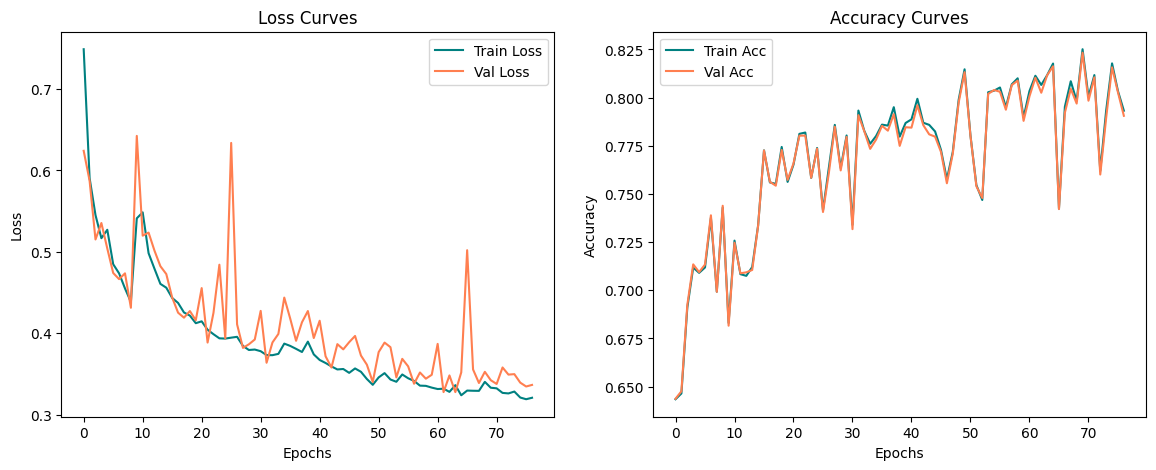

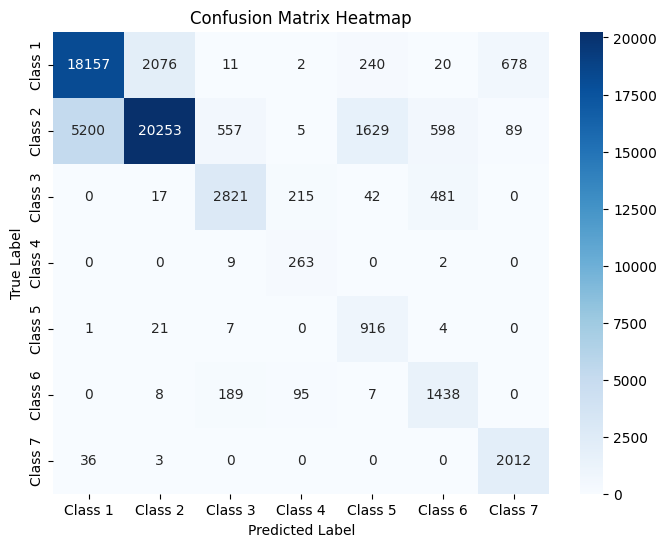

/tmp/ipykernel_5931/1863582046.py:222: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f"Class {i+1}" for i in range(7)], y=f1_scores, palette="magma")


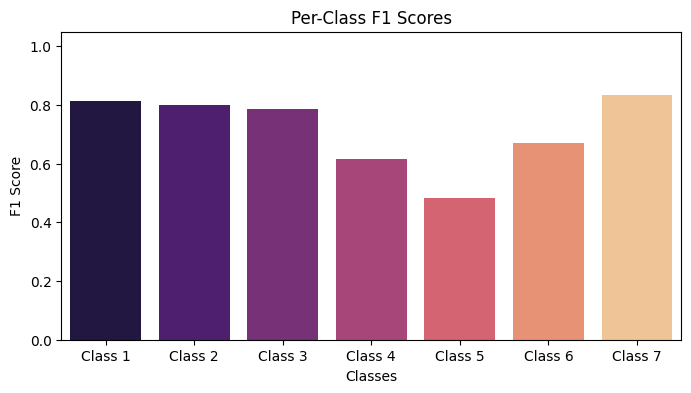

In [5]:

# PROGRAM: Deep Feed-Forward Neural Network (DFNN) for Multi-Class Classification

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# 1. Load the Covertype dataset
covtype = fetch_covtype()
X, y = covtype.data, covtype.target

# Convert target classes from 1-7 to 0-6
y_zero_indexed = y - 1
n_classes = 7

# 2. Partition dataset into train (80%), validation (10%), and testing (10%) sets with stratification
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_zero_indexed, test_size=0.2, random_state=42, stratify=y_zero_indexed
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# One-hot encode labels
def one_hot_encode(labels, classes=7):
    return np.eye(classes)[labels]

y_train_oh = one_hot_encode(y_train, n_classes)
y_val_oh = one_hot_encode(y_val, n_classes)
y_test_oh = one_hot_encode(y_test, n_classes)

# 3. Calculate class weights: w_c = N / (K * n_c)
class_counts = np.bincount(y_train)
class_weights = len(y_train) / (n_classes * class_counts)

# 4. Neural Network Architecture Definition & Parameter Initialization
layers = [54, 64, 32, 16, 7]

def initialize_parameters(layers_dims):
    np.random.seed(42)
    parameters = {}
    for l in range(1, len(layers_dims)):
        # He Initialization
        parameters[f'W{l}'] = np.random.randn(layers_dims[l], layers_dims[l-1]) * np.sqrt(2.0 / layers_dims[l-1])
        parameters[f'b{l}'] = np.zeros((layers_dims[l], 1))
    return parameters

# Activation Functions
def relu(Z):
    return np.maximum(0, Z)

def relu_derivative(Z):
    return (Z > 0).astype(float)

def softmax(Z):
    shift_Z = Z - np.max(Z, axis=0, keepdims=True)
    exps = np.exp(shift_Z)
    return exps / np.sum(exps, axis=0, keepdims=True)

# 5. Forward and Backward Propagation
def forward_propagation(X, parameters):
    cache = {"a0": X}
    L = len(parameters) // 2

    for l in range(1, L):
        Z = np.dot(parameters[f'W{l}'], cache[f'a{l-1}']) + parameters[f'b{l}']
        cache[f'z{l}'] = Z
        cache[f'a{l}'] = relu(Z)

    ZL = np.dot(parameters[f'W{L}'], cache[f'a{L-1}']) + parameters[f'b{L}']
    cache[f'z{L}'] = ZL
    cache[f'a{L}'] = softmax(ZL)

    return cache[f'a{L}'], cache

def compute_weighted_loss(A_last, Y, class_weights):
    batch_size = Y.shape[1]
    weighted_y = Y * class_weights[:, np.newaxis]
    loss = -np.sum(weighted_y * np.log(A_last + 1e-15)) / batch_size
    return loss

def backpropagation(parameters, cache, Y, class_weights):
    grads = {}
    L = len(parameters) // 2
    m = Y.shape[1]

    AL = cache[f'a{L}']
    sample_weights = np.sum(Y * class_weights[:, np.newaxis], axis=0, keepdims=True)
    dZL = (AL - Y) * sample_weights

    grads[f'dW{L}'] = np.dot(dZL, cache[f'a{L-1}'].T) / m
    grads[f'db{L}'] = np.sum(dZL, axis=1, keepdims=True) / m

    dZ = dZL
    for l in reversed(range(1, L)):
        da = np.dot(parameters[f'W{l+1}'].T, dZ)
        dZ = da * relu_derivative(cache[f'z{l}'])
        grads[f'dW{l}'] = np.dot(dZ, cache[f'a{l-1}'].T) / m
        grads[f'db{l}'] = np.sum(dZ, axis=1, keepdims=True) / m

    return grads

def update_parameters(parameters, grads, lr):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters[f'W{l}'] -= lr * grads[f'dW{l}']
        parameters[f'b{l}'] -= lr * grads[f'db{l}']
    return parameters

# 6. Model Training with SGD and Early Stopping
batch_size = 128
epochs = 150
learning_rate = 0.05
patience = 15

parameters = initialize_parameters(layers)
train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_loss = float('inf')
best_parameters = None
patience_counter = 0
num_samples_train = X_train.shape[0]

for epoch in range(epochs):
    shuffled_indices = np.random.permutation(num_samples_train)
    X_train_shuffled = X_train[shuffled_indices]
    y_train_oh_shuffled = y_train_oh[shuffled_indices]

    epoch_loss = 0
    num_batches = int(np.ceil(num_samples_train / batch_size))

    for b in range(num_batches):
        start_idx = b * batch_size
        end_idx = min(start_idx + batch_size, num_samples_train)

        x_batch = X_train_shuffled[start_idx:end_idx].T
        y_batch = y_train_oh_shuffled[start_idx:end_idx].T

        A_last, cache = forward_propagation(x_batch, parameters)
        loss = compute_weighted_loss(A_last, y_batch, class_weights)
        epoch_loss += loss * (end_idx - start_idx)

        grads = backpropagation(parameters, cache, y_batch, class_weights)
        parameters = update_parameters(parameters, grads, learning_rate)

    epoch_loss /= num_samples_train

    # Validation step
    A_val, _ = forward_propagation(X_val.T, parameters)
    val_loss = compute_weighted_loss(A_val, y_val_oh.T, class_weights)

    A_train, _ = forward_propagation(X_train.T, parameters)
    train_acc = np.mean(np.argmax(A_train, axis=0) == y_train)
    val_acc = np.mean(np.argmax(A_val, axis=0) == y_val)

    train_losses.append(epoch_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    # Early stopping evaluation
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_parameters = parameters.copy()
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d} | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

    if patience_counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}.")
        parameters = best_parameters
        break

# 7. Final Model Evaluation on Test Dataset
A_test, _ = forward_propagation(X_test.T, parameters)
y_pred = np.argmax(A_test, axis=0)

print("\n--- Evaluation Classification Report ---")
print(classification_report(y_test, y_pred, target_names=[f"Class {i+1}" for i in range(7)]))

# 8. Generation of Required Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, label='Train Loss', color='teal')
axes[0].plot(val_losses, label='Val Loss', color='coral')
axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(train_accs, label='Train Acc', color='teal')
axes[1].plot(val_accs, label='Val Acc', color='coral')
axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
plt.show()

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f"Class {i+1}" for i in range(7)],
            yticklabels=[f"Class {i+1}" for i in range(7)])
plt.title("Confusion Matrix Heatmap")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

f1_scores = f1_score(y_test, y_pred, average=None)
plt.figure(figsize=(8, 4))
sns.barplot(x=[f"Class {i+1}" for i in range(7)], y=f1_scores, palette="magma")
plt.title("Per-Class F1 Scores")
plt.xlabel("Classes")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)
plt.show()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 68s 35ms/step - accuracy: 0.9543 - loss: 0.1454 - val_accuracy: 0.9872 - val_loss: 0.0415
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 76s 41ms/step - accuracy: 0.9856 - loss: 0.0447 - val_accuracy: 0.9856 - val_loss: 0.0447
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 74s 36ms/step - accuracy: 0.9894 - loss: 0.0334 - val_accuracy: 0.9901 - val_loss: 0.0312
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.9923 - loss: 0.0250 - val_accuracy: 0.9882 - val_loss: 0.0394
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 78s 42ms/step - accuracy: 0.9936 - loss: 0.0195 - val_accuracy: 0.9892 - val_loss: 0.0373
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9892 - loss: 0.0373

Test accuracy 0.9891999959945679


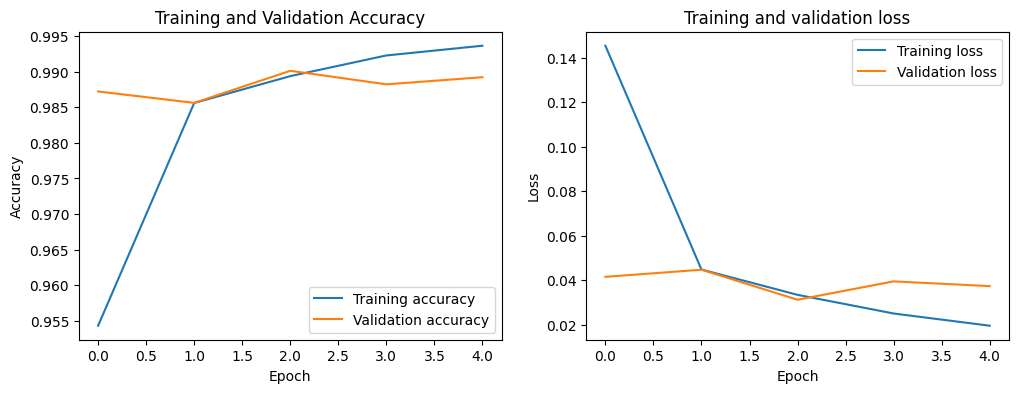

In [6]:
#PROGRAM: MNIST Image Classification using Convolutional Neural Networks (CNN)

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

train_images = train_images.reshape((train_images.shape[0], 28, 28, 1))
test_images = test_images.reshape((test_images.shape[0], 28, 28, 1))

train_images, test_images = train_images / 255.0, test_images / 255.0

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    train_images,
    train_labels,
    epochs=5,
    validation_data=(test_images, test_labels)
)

test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f"\nTest accuracy {test_acc}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title("Training and validation loss")

plt.show()